## Library / Resource Processing

In [25]:
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder

In [37]:
from torch.utils.tensorboard import SummaryWriter
import datetime

current_time = datetime.datetime.now().strftime('%Y%m%d-%H%M%S')
log_dir = f'runs/spectral_cnn_{current_time}'
writer = SummaryWriter(log_dir)

NameError: name 'device' is not defined

In [26]:
if torch.cuda.is_available():
    print("CUDA is available. You have", torch.cuda.device_count(), "GPUs.")

    for i in range(torch.cuda.device_count()):
        device_properties = torch.cuda.get_device_properties(i)
        device_name = device_properties.name
        vram_size = device_properties.total_memory / (1024 ** 3)  # Convert from bytes to gigabytes
        compute_capability = device_properties.major * 10 + device_properties.minor

        print(f"GPU {i}:")
        print(f"- Name: {device_name}")
        print(f"- VRAM Size: {vram_size:.2f} GB")
        print(f"- Compute Capability: {compute_capability}")
        print(f"- SM Count: {device_properties.multi_processor_count}\n")

else:
    print("CUDA is not available.")

CUDA is available. You have 1 GPUs.
GPU 0:
- Name: NVIDIA GeForce RTX 3080 Ti
- VRAM Size: 11.75 GB
- Compute Capability: 86
- SM Count: 80



In [27]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

## Data Organization and Visualization (Logger_v1 data processor)

In [28]:
def process_spectral_data(organic_file, inorganic_file):
    """
    Process spectral data from organic and inorganic CSV files.
    """
    # Define wavelength column names
    wavelengths = ['410nm', '435nm', '460nm', '485nm', '510nm', '535nm', 
                  '560nm', '585nm', '610nm', '645nm', '680nm', '705nm', 
                  '730nm', '760nm', '810nm', '860nm', '900nm', '940nm']
    
    def process_file(file_path):
        # Read all lines
        with open(file_path, 'r') as f:
            lines = f.readlines()
        
        # Process data lines
        data_rows = []
        labels = []
        
        for i in range(0, len(lines), 2):  # Process pairs of lines
            # Get spectral values and remove trailing comma if present
            spectral_values = lines[i].strip().rstrip(',').split(',')
            data_rows.append(spectral_values)
            
            # Get label
            label = lines[i+1].strip()
            labels.append(label)
        
        # Create DataFrame
        df = pd.DataFrame(data_rows, columns=wavelengths)
        df['Label'] = labels
        
        # Convert spectral values to float
        df[wavelengths] = df[wavelengths].astype(float)
        
        return df

    try:
        # Process both files
        organic_df = process_file(organic_file)
        inorganic_df = process_file(inorganic_file)
        
        # Add category column
        organic_df['Category'] = 'Organic'
        inorganic_df['Category'] = 'Inorganic'
        
        # Combine datasets
        combined_df = pd.concat([organic_df, inorganic_df], ignore_index=True)
        
        return organic_df, inorganic_df, combined_df
    
    except Exception as e:
        print(f"Error processing files: {e}")
        return None, None, None


In [29]:
def display_data_info(organic_df, inorganic_df, combined_df):
    """
    Display detailed information about the datasets
    """
    # Display basic information
    print("\n=== Dataset Information ===")
    print(f"Organic samples: {len(organic_df)}")
    print(f"Inorganic samples: {len(inorganic_df)}")
    print(f"Total samples: {len(combined_df)}")
    
    # Display first few rows of each dataset
    print("\n=== First Few Rows of Organic Data ===")
    print(organic_df.head(2))
    print("\n=== First Few Rows of Inorganic Data ===")
    print(inorganic_df.head(2))
    
    # Display basic statistics
    print("\n=== Statistical Summary ===")
    wavelengths = organic_df.columns[:-2]  # Exclude Label and Category
    stats = combined_df[wavelengths].describe()
    pd.set_option('display.float_format', '{:.2f}'.format)
    print(stats)
    
    # Display sample distribution
    print("\n=== Sample Distribution ===")
    print(combined_df.groupby(['Category', 'Label']).size().unstack(fill_value=0))


In [30]:
def plot_spectral_data(organic_df, inorganic_df, combined_df):
    """
    Create visualizations for the spectral data
    """
    wavelengths = organic_df.columns[:-2]  # Exclude Label and Category
    
    # Plot average spectral values
    plt.figure(figsize=(15, 5))
    plt.subplot(1, 2, 1)
    
    organic_mean = organic_df[wavelengths].mean()
    inorganic_mean = inorganic_df[wavelengths].mean()
    
    plt.plot(range(len(wavelengths)), organic_mean, 'b-', label='Organic')
    plt.plot(range(len(wavelengths)), inorganic_mean, 'r-', label='Inorganic')
    plt.xticks(range(len(wavelengths)), wavelengths, rotation=45)
    plt.title('Average Spectral Values')
    plt.legend()
    plt.grid(True)
    
    # Box plot
    plt.subplot(1, 2, 2)
    melted_df = pd.melt(combined_df, 
                        id_vars=['Category'], 
                        value_vars=wavelengths,
                        var_name='Wavelength',
                        value_name='Value')
    
    sns.boxplot(x='Category', y='Value', data=melted_df)
    plt.title('Distribution of Spectral Values')
    
    plt.tight_layout()
    plt.show()


=== Dataset Information ===
Organic samples: 29
Inorganic samples: 29
Total samples: 58

=== First Few Rows of Organic Data ===
   410nm  435nm   460nm  485nm  510nm  535nm  560nm  585nm  610nm  645nm  \
0  27.47 148.59 1625.51  37.75  62.70  70.31  56.42  55.52  94.72  28.62   
1  27.47 150.57 1637.66  37.75  63.43  71.02  56.92  55.99  95.82  28.62   

   680nm  705nm  730nm  760nm  810nm  860nm  900nm  940nm    Label Category  
0 198.21   9.27  21.80  49.83  10.01   6.23   9.59  22.88  organic  Organic  
1 199.21   9.27  21.80  49.83  10.01   6.23   9.59  22.88  organic  Organic  

=== First Few Rows of Inorganic Data ===
   410nm  435nm  460nm  485nm  510nm  535nm  560nm  585nm   610nm  645nm  \
0 828.15 229.82 687.57 115.94 492.13 392.72 100.24 158.57 1161.95 315.66   
1 702.91 201.09 594.15  97.07 446.20 336.62 100.24 159.51 1134.42 312.39   

   680nm  705nm  730nm  760nm  810nm  860nm  900nm  940nm      Label  \
0 589.66  63.34 144.82  83.31 320.31 860.33  88.72  15.56  inorga

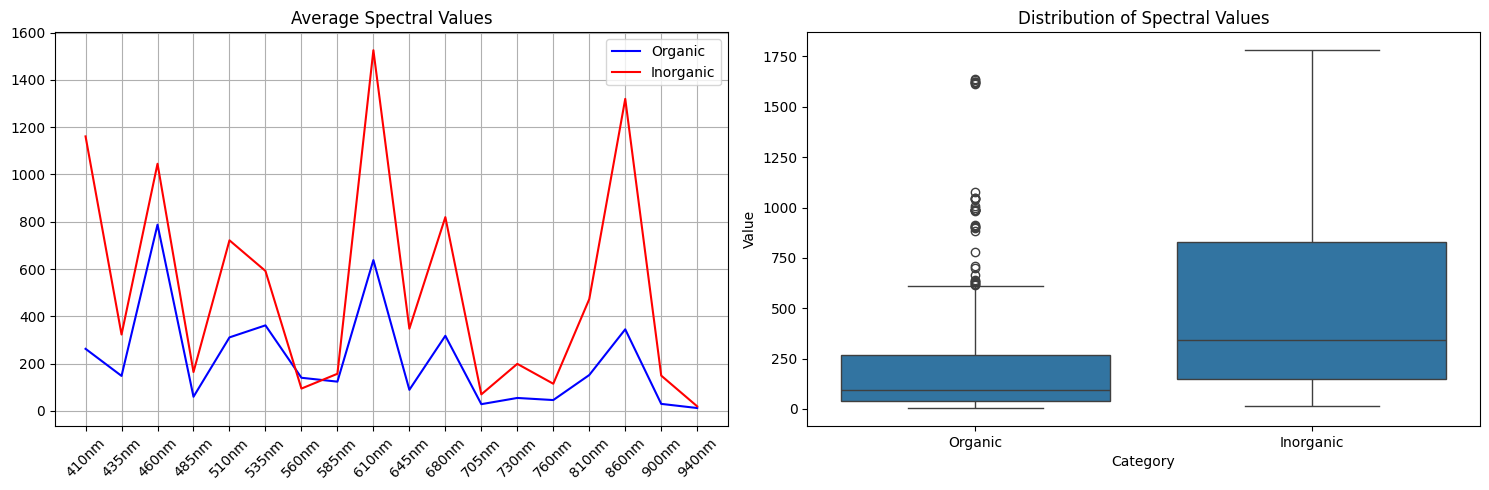


Processed data saved to 'processed_spectral_data.csv'


In [31]:
def main():
    # File paths - update these to your file paths
    organic_file = './demo_train/OrganicData.csv'
    inorganic_file = './demo_train/InorganicData.csv'
    
    # Process data
    organic_df, inorganic_df, combined_df = process_spectral_data(organic_file, inorganic_file)
    
    if combined_df is not None:
        # Display information
        display_data_info(organic_df, inorganic_df, combined_df)
        
        # Create visualizations
        plot_spectral_data(organic_df, inorganic_df, combined_df)
        
        # Save processed data
        combined_df.to_csv('processed_spectral_data.csv', index=False)
        print("\nProcessed data saved to 'processed_spectral_data.csv'")

if __name__ == "__main__":
    main()

## Model Training Setup

In [32]:
class SpectralDataset(Dataset):
    def __init__(self, X, y):
        self.X = torch.FloatTensor(X)
        self.y = torch.FloatTensor(y)
        
    def __len__(self):
        return len(self.X)
    
    def __getitem__(self, idx):
        return self.X[idx], self.y[idx]

In [33]:
class SpectralCNN(nn.Module):
    def __init__(self):
        super(SpectralCNN, self).__init__()
        
        # First Convolutional Layer
        self.conv1 = nn.Sequential(
            nn.Conv1d(in_channels=1, out_channels=16, kernel_size=3, stride=1, padding=1),
            nn.ReLU(),
            nn.MaxPool1d(kernel_size=2)
        )
        
        # Second Convolutional Layer
        self.conv2 = nn.Sequential(
            nn.Conv1d(in_channels=16, out_channels=32, kernel_size=3, stride=1, padding=1),
            nn.ReLU(),
            nn.MaxPool1d(kernel_size=2)
        )
        
        # Fully Connected Layers
        self.fc = nn.Sequential(
            nn.Linear(32 * 4, 64),
            nn.ReLU(),
            nn.Dropout(0.5),
            nn.Linear(64, 1),
            nn.Sigmoid()
        )
        
    def forward(self, x):
        x = x.unsqueeze(1)  # Add channel dimension
        x = self.conv1(x)
        x = self.conv2(x)
        x = x.view(x.size(0), -1)  # Flatten
        x = self.fc(x)
        return x

Epoch [1/50], Loss: 26.2147, Test Accuracy: 75.00%
Epoch [2/50], Loss: 7.7638, Test Accuracy: 100.00%
Epoch [3/50], Loss: 7.6856, Test Accuracy: 100.00%
Epoch [4/50], Loss: 6.8390, Test Accuracy: 100.00%
Epoch [5/50], Loss: 11.9467, Test Accuracy: 100.00%
Epoch [6/50], Loss: 7.0984, Test Accuracy: 100.00%
Epoch [7/50], Loss: 4.8612, Test Accuracy: 91.67%
Epoch [8/50], Loss: 3.8460, Test Accuracy: 100.00%
Epoch [9/50], Loss: 1.9292, Test Accuracy: 100.00%
Epoch [10/50], Loss: 0.2127, Test Accuracy: 100.00%
Epoch [11/50], Loss: 1.9491, Test Accuracy: 100.00%
Epoch [12/50], Loss: 2.1472, Test Accuracy: 100.00%
Epoch [13/50], Loss: 1.2347, Test Accuracy: 100.00%
Epoch [14/50], Loss: 0.0993, Test Accuracy: 100.00%
Epoch [15/50], Loss: 0.3541, Test Accuracy: 100.00%
Epoch [16/50], Loss: 0.4038, Test Accuracy: 100.00%
Epoch [17/50], Loss: 0.0465, Test Accuracy: 100.00%
Epoch [18/50], Loss: 0.0457, Test Accuracy: 100.00%
Epoch [19/50], Loss: 0.1196, Test Accuracy: 100.00%
Epoch [20/50], Loss: 

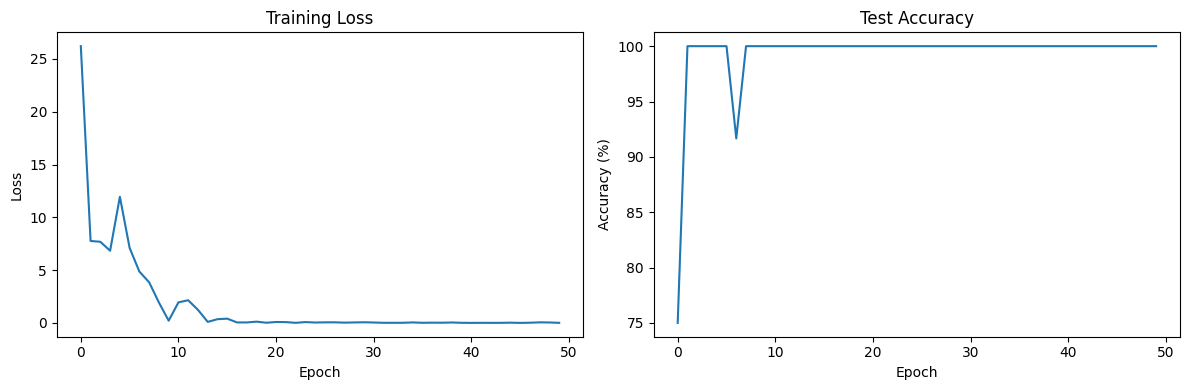


Classification Report:
              precision    recall  f1-score   support

   inorganic       1.00      1.00      1.00         6
     organic       1.00      1.00      1.00         6

    accuracy                           1.00        12
   macro avg       1.00      1.00      1.00        12
weighted avg       1.00      1.00      1.00        12


Confusion Matrix:
[[6 0]
 [0 6]]

Model saved as 'spectral_classifier.pth'


In [42]:
def train_and_evaluate():
    # 1. Load and prepare data
    data = pd.read_csv('processed_spectral_data.csv')
    
    # Separate features and labels
    X = data.iloc[:, :18].values  # First 18 columns are spectral data
    y = data['Label'].values      # 'Label' column
    
    # Encode labels (organic/inorganic) to 0/1
    le = LabelEncoder()
    y = le.fit_transform(y)
    
    # Split data
    X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
    
    # Create datasets
    train_dataset = SpectralDataset(X_train, y_train)
    test_dataset = SpectralDataset(X_test, y_test)
    
    # Create data loaders
    train_loader = DataLoader(train_dataset, batch_size=32, shuffle=True)
    test_loader = DataLoader(test_dataset, batch_size=32)

    num_epochs = 50
    train_losses = []
    test_accuracies = []
    
    device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
    model = SpectralCNN().to(device)
    criterion = nn.BCELoss()
    optimizer = optim.Adam(model.parameters(), lr=0.001)
    
    # Initialize TensorBoard
    current_time = datetime.datetime.now().strftime('%Y%m%d-%H%M%S')
    log_dir = f'runs/spectral_cnn_{current_time}'
    writer = SummaryWriter(log_dir)
    
    # Add model graph
    dummy_input = torch.randn(1, 18).to(device)
    writer.add_graph(model, dummy_input)

    
    # Training loop
    for epoch in range(num_epochs):
        model.train()
        total_loss = 0
        
        # Training phase
        for inputs, labels in train_loader:
            inputs, labels = inputs.to(device), labels.to(device)
            
            optimizer.zero_grad()
            outputs = model(inputs)
            loss = criterion(outputs.squeeze(), labels)
            loss.backward()
            optimizer.step()
            
            total_loss += loss.item()
        
        avg_loss = total_loss / len(train_loader)
        train_losses.append(avg_loss)
        
        # Evaluation phase
        model.eval()
        correct = 0
        total = 0
        with torch.no_grad():
            for inputs, labels in test_loader:
                inputs, labels = inputs.to(device), labels.to(device)
                outputs = model(inputs)
                predicted = (outputs.squeeze() > 0.5).float()
                total += labels.size(0)
                correct += (predicted == labels).sum().item()
        
        accuracy = 100 * correct / total
        test_accuracies.append(accuracy)
        
        # Log to TensorBoard
        writer.add_scalar('Training/Loss', avg_loss, epoch)
        writer.add_scalar('Training/Accuracy', accuracy, epoch)
        writer.add_scalar('Training/Learning_Rate', optimizer.param_groups[0]['lr'], epoch)
        
        # Log model parameters
        for name, param in model.named_parameters():
            writer.add_histogram(f'Parameters/{name}', param.data, epoch)
            if param.grad is not None:
                writer.add_histogram(f'Gradients/{name}', param.grad, epoch)
        
        print(f'Epoch [{epoch+1}/{num_epochs}], Loss: {avg_loss:.4f}, Test Accuracy: {accuracy:.2f}%')

    writer.close()
    # 4. Plot training results
    plt.figure(figsize=(12, 4))
    
    plt.subplot(1, 2, 1)
    plt.plot(train_losses)
    plt.title('Training Loss')
    plt.xlabel('Epoch')
    plt.ylabel('Loss')
    
    plt.subplot(1, 2, 2)
    plt.plot(test_accuracies)
    plt.title('Test Accuracy')
    plt.xlabel('Epoch')
    plt.ylabel('Accuracy (%)')
    
    plt.tight_layout()
    plt.show()
    
    # 5. Final evaluation
    model.eval()
    y_pred = []
    y_true = []
    
    with torch.no_grad():
        for inputs, labels in test_loader:
            inputs, labels = inputs.to(device), labels.to(device)
            outputs = model(inputs)
            predicted = (outputs.squeeze() > 0.5).float()
            y_pred.extend(predicted.cpu().numpy())
            y_true.extend(labels.cpu().numpy())
    
    # Print classification metrics
    from sklearn.metrics import classification_report, confusion_matrix
    print("\nClassification Report:")
    print(classification_report(y_true, y_pred, target_names=le.classes_))
    
    print("\nConfusion Matrix:")
    print(confusion_matrix(y_true, y_pred))
    
    # Save the model
    torch.save(model.state_dict(), 'spectral_classifier.pth')
    print("\nModel saved as 'spectral_classifier.pth'")

if __name__ == "__main__":
    train_and_evaluate()

## Inference with .pth file

In [43]:
class SpectralCNN(nn.Module):
    def __init__(self):
        super(SpectralCNN, self).__init__()
        
        # First Convolutional Layer
        self.conv1 = nn.Sequential(
            nn.Conv1d(in_channels=1, out_channels=16, kernel_size=3, stride=1, padding=1),
            nn.ReLU(),
            nn.MaxPool1d(kernel_size=2)
        )
        
        # Second Convolutional Layer
        self.conv2 = nn.Sequential(
            nn.Conv1d(in_channels=16, out_channels=32, kernel_size=3, stride=1, padding=1),
            nn.ReLU(),
            nn.MaxPool1d(kernel_size=2)
        )
        
        # Fully Connected Layers
        self.fc = nn.Sequential(
            nn.Linear(32 * 4, 64),
            nn.ReLU(),
            nn.Dropout(0.5),
            nn.Linear(64, 1),
            nn.Sigmoid()
        )
        
    def forward(self, x):
        x = x.unsqueeze(1)
        x = self.conv1(x)
        x = self.conv2(x)
        x = x.view(x.size(0), -1)
        x = self.fc(x)
        return x

In [44]:
def predict_sample(sample_data):
    # Set device
    device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
    
    # Load the trained model
    model = SpectralCNN().to(device)
    model.load_state_dict(torch.load('spectral_classifier.pth'))
    model.eval()  # Set to evaluation mode
    
    # Prepare the input data
    # Assuming sample_data is a list or numpy array of 18 values
    sample_tensor = torch.FloatTensor(sample_data).to(device)
    
    # Add batch dimension
    sample_tensor = sample_tensor.unsqueeze(0)  # Shape becomes [1, 18]
    
    # Perform inference
    with torch.no_grad():
        output = model(sample_tensor)
        probability = output.item()
        prediction = 1 if probability >= 0.5 else 0
        
    return prediction, probability

In [61]:
if __name__ == "__main__":
    # Example sample data (18 wavelength values)
    sample = [58.98,45.57,161.62,26.06,116.65,159.08,89.16,68.70,269.84,35.98,129.49,16.99,21.02,17.91,65.06,151.70,11.99,4.58]
    
    prediction, probability = predict_sample(sample)
    
    print("\nInput Sample:")
    print("Wavelength values:", sample)
    print("\nPrediction Results:")
    print(f"Class: {'Organic' if prediction == 1 else 'Inorganic'}")
    print(f"Confidence: {probability*100:.2f}%")


Input Sample:
Wavelength values: [58.98, 45.57, 161.62, 26.06, 116.65, 159.08, 89.16, 68.7, 269.84, 35.98, 129.49, 16.99, 21.02, 17.91, 65.06, 151.7, 11.99, 4.58]

Prediction Results:
Class: Organic
Confidence: 93.28%


/tmp/ipykernel_21922/3559076855.py:7: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  model.load_state_dict(torch.load('spectral_classifier.pth'))
